<a href="https://colab.research.google.com/github/aarushi-202618017/202618017_Aarushi_DS605/blob/main/202618017_LAB_08/202618017_LAB_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
! pip install ucimlrepo

In [7]:
from ucimlrepo import fetch_ucirepo

banknote_authentication = fetch_ucirepo(id=267)
X = banknote_authentication.data.features
y = banknote_authentication.data.targets.values.ravel()

# Part A - Decision Tree from Scratch

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X_2d = X[['variance', 'skewness']].values

X_train, X_test, y_train, y_test = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)

X_train, X_test, y_train, y_test = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)

In [9]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, *, value=None, impurity=None, n_samples=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.impurity = impurity
        self.n_samples = n_samples

    def is_leaf_node(self):
        return self.value is not None

class DecisionTreeScratch:
    def __init__(self, criterion='gini', max_depth=5, min_samples_split=2):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def _impurity(self, y):
        if len(y) == 0:
            return 0.0
        p = np.bincount(y) / len(y)
        p = p[p > 0]
        if self.criterion == 'gini':
            return 1.0 - np.sum(p ** 2)
        elif self.criterion == 'entropy':
            return -np.sum(p * np.log2(p))
        else:
            raise ValueError(f"Unknown criterion: {self.criterion}")

    def _information_gain(self, y, X_column, threshold):
        parent_impurity = self._impurity(y)
        left_mask = X_column <= threshold
        right_mask = ~left_mask
        if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
            return 0.0
        n = len(y)
        n_l, n_r = np.sum(left_mask), np.sum(right_mask)
        imp_l = self._impurity(y[left_mask])
        imp_r = self._impurity(y[right_mask])
        child_impurity = (n_l / n) * imp_l + (n_r / n) * imp_r
        return parent_impurity - child_impurity

    def _best_split(self, X, y):
        best_gain = -1.0
        split_idx, split_thresh = None, None
        n_features = X.shape[1]
        for feat_idx in range(n_features):
            X_column = X[:, feat_idx]
            thresholds = np.unique(X_column)
            if len(thresholds) > 1:
                midpoints = (thresholds[:-1] + thresholds[1:]) / 2.0
            else:
                midpoints = thresholds
            for thresh in midpoints:
                gain = self._information_gain(y, X_column, thresh)
                if gain > best_gain:
                    best_gain = gain
                    split_idx = feat_idx
                    split_thresh = thresh
        return split_idx, split_thresh

    def fit(self, X, y):
        self.root = self._grow_tree(X, y)

    def _grow_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        n_labels = len(np.unique(y))
        current_impurity = self._impurity(y)
        if (depth >= self.max_depth or n_labels <= 1 or n_samples < self.min_samples_split):
            leaf_val = np.bincount(y).argmax() if len(y) > 0 else 0
            return Node(value=leaf_val, impurity=current_impurity, n_samples=n_samples)

        best_feat, best_thresh = self._best_split(X, y)
        if best_feat is None:
            leaf_val = np.bincount(y).argmax()
            return Node(value=leaf_val, impurity=current_impurity, n_samples=n_samples)

        left_mask = X[:, best_feat] <= best_thresh
        right_mask = ~left_mask
        left_child = self._grow_tree(X[left_mask], y[left_mask], depth + 1)
        right_child = self._grow_tree(X[right_mask], y[right_mask], depth + 1)
        return Node(
            feature=best_feat,
            threshold=best_thresh,
            left=left_child,
            right=right_child,
            impurity=current_impurity,
            n_samples=n_samples
        )

    def predict(self, X):
        return np.array([self._traverse_tree(x, self.root) for x in X])

    def _traverse_tree(self, x, node):
        if node.is_leaf_node():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse_tree(x, node.left)
        return self._traverse_tree(x, node.right)

    def print_tree(self, node=None, depth=0, feature_names=['variance', 'skewness']):
        if node is None:
            node = self.root
        indent = "  | " * depth
        if node.is_leaf_node():
            print(f"{indent}-> Leaf: Class {node.value} (Samples: {node.n_samples}, Impurity: {node.impurity:.4f})")
        else:
            feat_name = feature_names[node.feature] if feature_names else f"X[{node.feature}]"
            print(f"{indent}[{feat_name} <= {node.threshold:.4f}] (Samples: {node.n_samples}, Impurity: {node.impurity:.4f})")
            self.print_tree(node.left, depth + 1, feature_names)
            self.print_tree(node.right, depth + 1, feature_names)


[variance <= 0.7651] (Samples: 1097, Impurity: 0.4939)
  | [skewness <= 5.1608] (Samples: 593, Impurity: 0.3589)
  |   | [variance <= 0.3202] (Samples: 464, Impurity: 0.1646)
  |   |   | [variance <= -0.4586] (Samples: 413, Impurity: 0.0922)
  |   |   |   | -> Leaf: Class 1 (Samples: 346, Impurity: 0.0507)
  |   |   |   | -> Leaf: Class 1 (Samples: 67, Impurity: 0.2744)
  |   |   | [skewness <= 3.2197] (Samples: 51, Impurity: 0.4906)
  |   |   |   | -> Leaf: Class 0 (Samples: 39, Impurity: 0.4918)
  |   |   |   | -> Leaf: Class 1 (Samples: 12, Impurity: 0.0000)
  |   | [variance <= -3.4311] (Samples: 129, Impurity: 0.3731)
  |   |   | [variance <= -4.3819] (Samples: 32, Impurity: 0.0605)
  |   |   |   | -> Leaf: Class 1 (Samples: 29, Impurity: 0.0000)
  |   |   |   | -> Leaf: Class 1 (Samples: 3, Impurity: 0.4444)
  |   |   | [skewness <= 5.3646] (Samples: 97, Impurity: 0.0204)
  |   |   |   | -> Leaf: Class 0 (Samples: 2, Impurity: 0.5000)
  |   |   |   | -> Leaf: Class 0 (Samples: 95

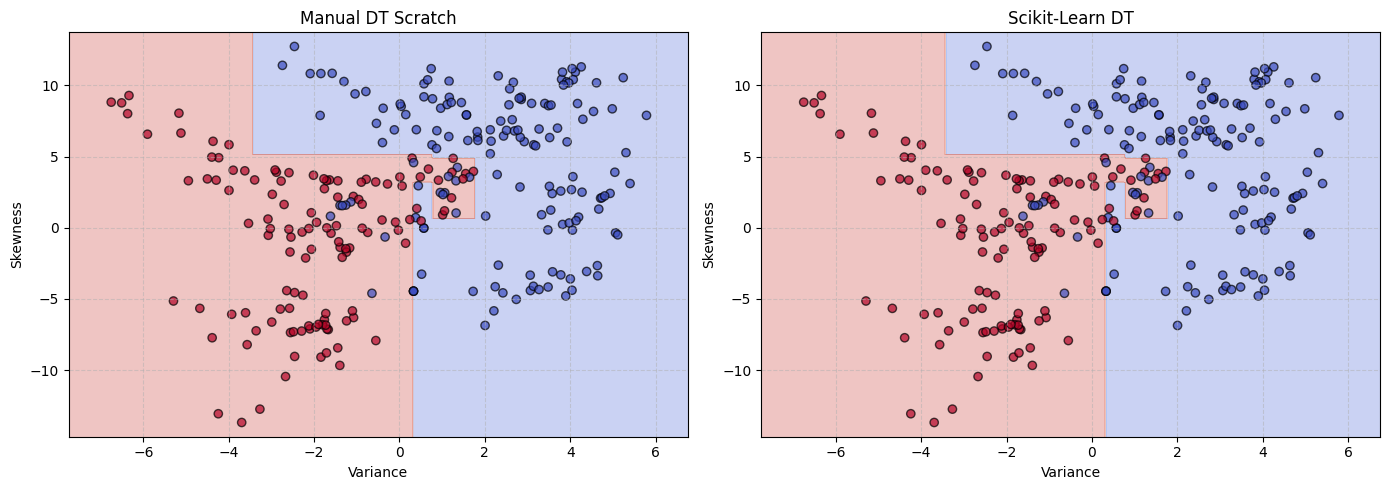

In [11]:
manual_tree = DecisionTreeScratch(criterion='gini', max_depth=4)
manual_tree.fit(X_train, y_train)

sklearn_tree = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
sklearn_tree.fit(X_train, y_train)

manual_tree.print_tree(feature_names=['variance', 'skewness'])

def plot_decision_boundaries(model_manual, model_sklearn, X, y):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05), np.arange(y_min, y_max, 0.05))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    models = [("Manual DT Scratch", model_manual), ("Scikit-Learn DT", model_sklearn)]

    for ax, (name, model) in zip(axes, models):
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.7)
        ax.set_xlabel("Variance")
        ax.set_ylabel("Skewness")
        ax.set_title(name)
        ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

plot_decision_boundaries(manual_tree, sklearn_tree, X_test, y_test)

In [12]:
results = []
for criterion in ['gini', 'entropy']:
    for depth in [2, 4, 6, 8]:
        dt_m = DecisionTreeScratch(criterion=criterion, max_depth=depth)
        dt_m.fit(X_train, y_train)
        pred_m = dt_m.predict(X_test)

        dt_s = DecisionTreeClassifier(criterion=criterion, max_depth=depth, random_state=42)
        dt_s.fit(X_train, y_train)
        pred_s = dt_s.predict(X_test)

        results.append({
            'Criterion': criterion,
            'Max Depth': depth,
            'Manual Acc': accuracy_score(y_test, pred_m),
            'Sklearn Acc': accuracy_score(y_test, pred_s),
            'Manual F1': f1_score(y_test, pred_m),
            'Sklearn F1': f1_score(y_test, pred_s)
        })

df_results = pd.DataFrame(results)
print(df_results.to_string(index=False))

Criterion  Max Depth  Manual Acc  Sklearn Acc  Manual F1  Sklearn F1
     gini          2    0.876364     0.876364   0.859504    0.859504
     gini          4    0.934545     0.934545   0.930233    0.930233
     gini          6    0.927273     0.930909   0.921875    0.926070
     gini          8    0.916364     0.920000   0.909804    0.914062
  entropy          2    0.876364     0.876364   0.859504    0.859504
  entropy          4    0.909091     0.909091   0.900398    0.900398
  entropy          6    0.934545     0.938182   0.928571    0.932806
  entropy          8    0.927273     0.923636   0.920000    0.915663


# Part B - Linear SVM from Scratch

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class LinearSVMScratch:
    def __init__(self, C=1.0, lr=0.001, n_iters=1000):
        self.C = C
        self.lr = lr
        self.n_iters = n_iters
        self.w = None
        self.b = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        y_encoded = np.where(y <= 0, -1, 1)

        self.w = np.zeros(n_features)
        self.b = 0.0

        for epoch in range(self.n_iters):
            for idx, x_i in enumerate(X):
                condition = y_encoded[idx] * (np.dot(x_i, self.w) + self.b) >= 1
                if condition:
                    dw = self.w / n_samples
                    db = 0.0
                else:
                    dw = self.w / n_samples - self.C * y_encoded[idx] * x_i
                    db = -self.C * y_encoded[idx]

                self.w -= self.lr * dw
                self.b -= self.lr * db

    def decision_function(self, X):
        return np.dot(X, self.w) + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, 0)

manual_svm = LinearSVMScratch(C=1.0, lr=0.005, n_iters=1500)
manual_svm.fit(X_train_scaled, y_train)

sklearn_svm = SVC(kernel='linear', C=1.0)
sklearn_svm.fit(X_train_scaled, y_train)

SVC(kernel='linear')

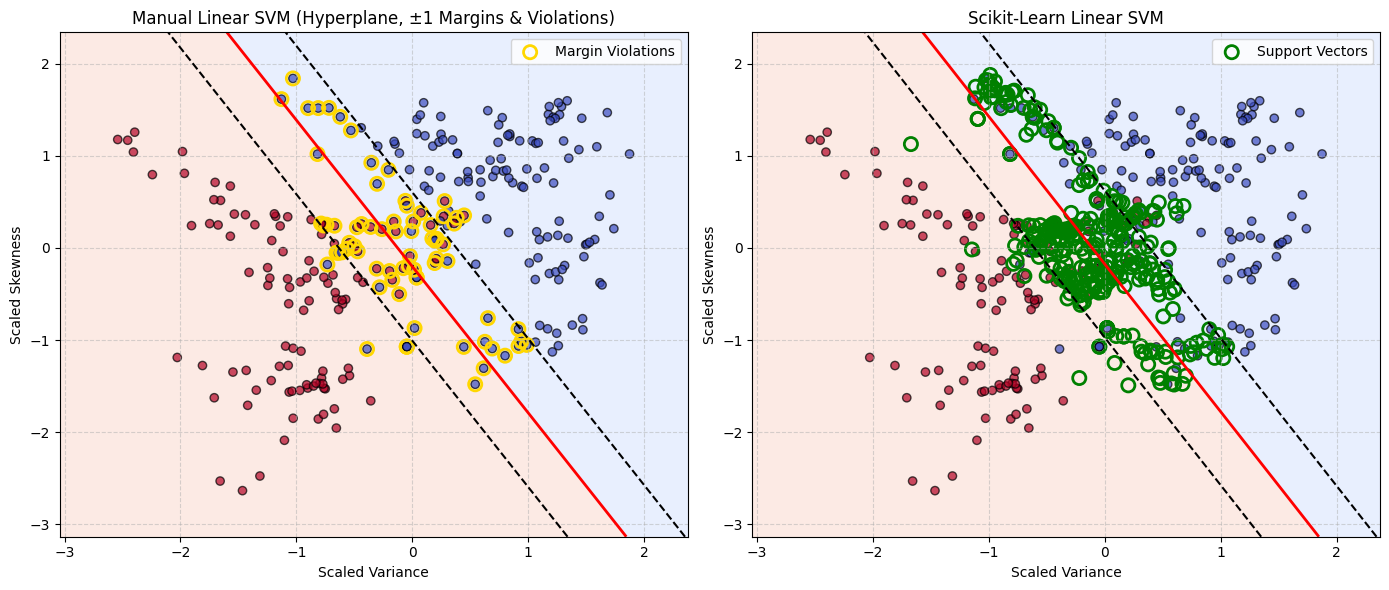

In [14]:
def plot_svm_boundaries(manual_model, sklearn_model, X_test_s, y_test_orig):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    x_min, x_max = X_test_s[:, 0].min() - 0.5, X_test_s[:, 0].max() + 0.5
    y_min, y_max = X_test_s[:, 1].min() - 0.5, X_test_s[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]

    y_encoded_test = np.where(y_test_orig <= 0, -1, 1)
    scores_manual = manual_model.decision_function(X_test_s)
    violations = y_encoded_test * scores_manual < 1

    Z_m = manual_model.decision_function(grid).reshape(xx.shape)
    axes[0].contourf(xx, yy, Z_m > 0, alpha=0.2, cmap=plt.cm.coolwarm)
    axes[0].contour(xx, yy, Z_m, levels=[-1, 0, 1], colors=['k', 'r', 'k'], linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])
    axes[0].scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test_orig, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.7)
    axes[0].scatter(X_test_s[violations, 0], X_test_s[violations, 1], s=90, facecolors='none', edgecolors='gold', linewidths=2, label='Margin Violations')
    axes[0].set_title("Manual Linear SVM (Hyperplane, ±1 Margins & Violations)")
    axes[0].set_xlabel("Scaled Variance")
    axes[0].set_ylabel("Scaled Skewness")
    axes[0].legend()
    axes[0].grid(True, linestyle='--', alpha=0.5)

    Z_s = sklearn_model.decision_function(grid).reshape(xx.shape)
    axes[1].contourf(xx, yy, Z_s > 0, alpha=0.2, cmap=plt.cm.coolwarm)
    axes[1].contour(xx, yy, Z_s, levels=[-1, 0, 1], colors=['k', 'r', 'k'], linestyles=['--', '-', '--'], linewidths=[1.5, 2, 1.5])
    axes[1].scatter(X_test_s[:, 0], X_test_s[:, 1], c=y_test_orig, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.7)
    axes[1].scatter(sklearn_model.support_vectors_[:, 0], sklearn_model.support_vectors_[:, 1], s=90, facecolors='none', edgecolors='green', linewidths=2, label='Support Vectors')
    axes[1].set_title("Scikit-Learn Linear SVM")
    axes[1].set_xlabel("Scaled Variance")
    axes[1].set_ylabel("Scaled Skewness")
    axes[1].legend()
    axes[1].grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

plot_svm_boundaries(manual_svm, sklearn_svm, X_test_scaled, y_test)


In [15]:
experiments = [
    {'C': 0.01, 'lr': 0.005, 'n_iters': 1500},
    {'C': 1.0,  'lr': 0.005, 'n_iters': 1500},
    {'C': 10.0, 'lr': 0.005, 'n_iters': 1500},
    {'C': 1.0,  'lr': 0.0001,'n_iters': 1500},
    {'C': 1.0,  'lr': 0.05,  'n_iters': 1500},
    {'C': 1.0,  'lr': 0.005, 'n_iters': 100},
    {'C': 1.0,  'lr': 0.005, 'n_iters': 3000},
]

param_results = []
for params in experiments:
    model = LinearSVMScratch(C=params['C'], lr=params['lr'], n_iters=params['n_iters'])
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    param_results.append({
        'C': params['C'],
        'Learning Rate': params['lr'],
        'Iterations': params['n_iters'],
        'Accuracy': accuracy_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds)
    })

df_params = pd.DataFrame(param_results)
print(df_params.to_string(index=False))

    C  Learning Rate  Iterations  Accuracy  F1-Score
 0.01         0.0050        1500  0.887273  0.869198
 1.00         0.0050        1500  0.880000  0.866397
10.00         0.0050        1500  0.869091  0.854839
 1.00         0.0001        1500  0.876364  0.862903
 1.00         0.0500        1500  0.876364  0.864000
 1.00         0.0050         100  0.880000  0.866397
 1.00         0.0050        3000  0.880000  0.866397


# Part C - Kernel SVM and Nonlinear Boundaries

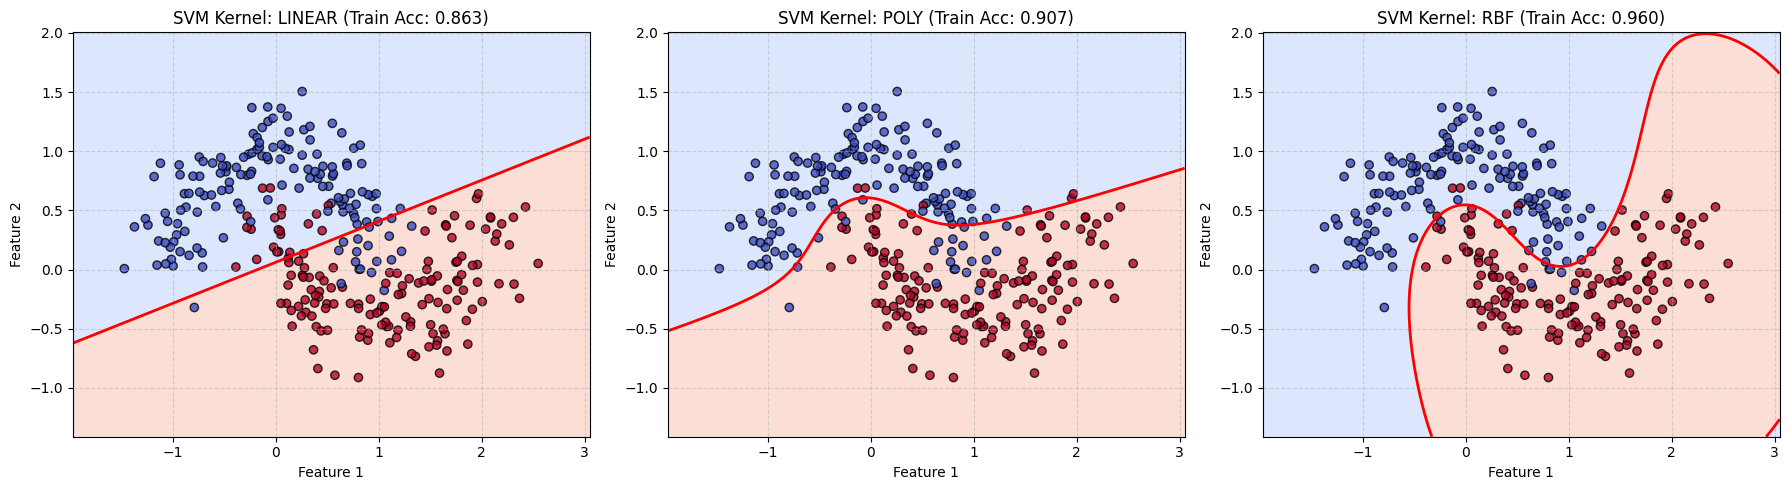

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

X_moons, y_moons = make_moons(n_samples=300, noise=0.2, random_state=42)

kernels = ['linear', 'poly', 'rbf']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

for ax, kernel in zip(axes, kernels):
    if kernel == 'poly':
        clf = SVC(kernel=kernel, degree=3, C=1.0)
    else:
        clf = SVC(kernel=kernel, C=1.0, gamma='scale')

    clf.fit(X_moons, y_moons)
    Z = clf.decision_function(grid).reshape(xx.shape)
    acc = accuracy_score(y_moons, clf.predict(X_moons))

    ax.contourf(xx, yy, Z > 0, alpha=0.3, cmap=plt.cm.coolwarm)
    ax.contour(xx, yy, Z, levels=[0], colors='r', linewidths=2)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.8)
    ax.set_title(f"SVM Kernel: {kernel.upper()} (Train Acc: {acc:.3f})")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Part D - Final Comparison

In [18]:


models = {
    'Manual Decision Tree': (DecisionTreeScratch(max_depth=5), X_train, X_test),
    'Scikit-Learn Decision Tree': (DecisionTreeClassifier(max_depth=5, random_state=42), X_train, X_test),
    'Manual Linear SVM': (LinearSVMScratch(C=1.0, lr=0.005, n_iters=1500), X_train_scaled, X_test_scaled),
    'Scikit-Learn Linear SVM': (SVC(kernel='linear', C=1.0), X_train_scaled, X_test_scaled),
    'Scikit-Learn RBF SVM': (SVC(kernel='rbf', C=1.0, gamma='scale'), X_train_scaled, X_test_scaled)
}

final_results = []
for name, (model, X_tr, X_te) in models.items():
    t0 = time.time()
    model.fit(X_tr, y_train)
    t_train = time.time() - t0

    t0 = time.time()
    preds = model.predict(X_te)
    t_pred = time.time() - t0

    final_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Train Time (s)': t_train,
        'Pred Time (s)': t_pred
    })

df_comparison = pd.DataFrame(final_results)
df_comparison

,Model,Accuracy,Precision,Recall,F1-Score,Train Time (s),Pred Time (s)
0,Manual Decision Tree,0.930909,0.881481,0.975410,0.926070,1.288503,0.000916
1,Scikit-Learn Decision Tree,0.930909,0.881481,0.975410,0.926070,0.004668,0.000434
2,Manual Linear SVM,0.880000,0.856000,0.877049,0.866397,21.463495,0.000058
3,Scikit-Learn Linear SVM,0.876364,0.849206,0.877049,0.862903,0.048770,0.011117
4,Scikit-Learn RBF SVM,0.923636,0.879699,0.959016,0.917647,0.057941,0.019420
